# RQ3 — Predicting Environmental Intensity (Sales)
**Group 11 · Data Mining**

**RQ3:** How accurately can environmental intensity be predicted from industry, country and year, including for companies not seen in training and for later periods?


## Design
1. **Target:** `environmental_intensity_sales` on its raw signed scale. Values are retained as supplied; the sign is not interpreted as a direct measure of physical environmental harm.
2. **Predictors:** `industry_exiobase`, `gics_sub_industry`, `country`, `year`. `pct_imputed`, cost, safeguard, SDG, company identity and `environmental_intensity_op_inc` are excluded to avoid target leakage or memorising firms.
3. **Benchmarks:** Exiobase industry median and GICS sub-industry median.
4. **Models:** Elastic Net, Random Forest and XGBoost (HistGradientBoosting fallback if XGBoost is missing).
5. **Test A (unseen companies):** 5-fold GroupKFold by company.
6. **Test B (later periods):** train on 2010–2016, test on 2017–2019, reported for all, seen and unseen companies. Hyperparameters are tuned only inside the training period.
7. **Metrics:** MAE is primary, RMSE and R² secondary, MAE skill is reported against both median benchmarks.
8. **What the predictions rely on, and stability:** grouped permutation importance, grouped SHAP, feature-family ablation, expanding-window backtest (2016–2019) and a low-imputation (≤5%) check.



In [ ]:
# Colab environment: run once before executing the notebook.
import sys
if sys.version_info >= (3, 13):
    raise RuntimeError(
        "Recommend Python 3.12 and report an installation failure on Python 3.13. "
        "Select a Python 3.12 runtime before installing the packages."
    )
%pip -q install cnsplots==0.8.0 xgboost openpyxl


In [ ]:
# Setup and data
import os, time, json
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
try:
    import xgboost as xgb; HAS_XGB = True
except Exception:
    HAS_XGB = False
BOOST = "XGBoost" if HAS_XGB else "Boosted trees (HistGB fallback)"
SEED = 42
OUT_DIR = os.environ.get("OUT_DIR", "rq3_outputs"); os.makedirs(OUT_DIR, exist_ok=True)
CLEANED_PATH = os.environ.get("CLEANED_PATH") or (
    "/content/cleaned_environmental_impact_data.xlsx"
    if os.path.exists("/content/cleaned_environmental_impact_data.xlsx")
    else "cleaned_environmental_impact_data.xlsx"
)
print("file:", CLEANED_PATH, "| xgboost:", HAS_XGB, "| boosted model:", BOOST)

df = pd.read_excel(CLEANED_PATH)
TEXT = ["company_name", "country", "gics_sub_industry", "industry_exiobase"]
for c in TEXT:
    df[c] = df[c].astype("string").str.replace("\xa0", " ", regex=False).str.strip().astype(object)
df = df.reset_index(drop=True)
TARGET, GROUP = "environmental_intensity_sales", "company_name"
CAT = ["industry_exiobase", "gics_sub_industry", "country"]; NUM = ["year"]; FEATS = CAT + NUM
ALLCATS = {c: sorted(set(df[c])) for c in CAT}
print(df.shape, "| firms", df[GROUP].nunique(), "| years", df.year.min(), "-", df.year.max())

file: /content/cleaned_environmental_impact_data.xlsx | xgboost: True | boosted model: XGBoost
(14015, 34) | firms 2485 | years 2010 - 2019


In [ ]:
# Models, metrics, and validation helpers
rmse = lambda y, p: float(np.sqrt(mean_squared_error(y, p)))

def metr(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(
        MAE=mean_absolute_error(y, p),
        RMSE=rmse(y, p),
        R2=r2_score(y, p),
        Spearman=spearmanr(y, p)[0] if np.std(p) > 0 else np.nan,
    )

class LevelMedian:
    # Median by level; if unseen, fall back to next level, then global median.
    def __init__(self, cols):
        self.cols = cols
    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.g = y.median()
        self.maps = [y.groupby(X[c].values).median() for c in self.cols]
        return self
    def predict(self, X):
        p = pd.Series(np.nan, index=X.index)
        for c, m in zip(self.cols, self.maps):
            p = p.fillna(pd.Series(X[c].map(m).values, index=X.index))
        return p.fillna(self.g).values

def _pre(feats, scale_num):
    cats = [f for f in feats if f in CAT]
    nums = [f for f in feats if f in NUM]
    t = [("c", OneHotEncoder(handle_unknown="ignore"), cats)]
    if nums:
        t.append(("n", StandardScaler() if scale_num else "passthrough", nums))
    return ColumnTransformer(t)

def make_enet(feats=FEATS, alpha=0.001, l1=0.5):
    return Pipeline([
        ("p", _pre(feats, True)),
        ("m", ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=20000, random_state=SEED)),
    ])

class _Feats:
    def __init__(self, est, feats):
        self.est, self.feats = est, feats
    def fit(self, X, y):
        self.est.fit(X[self.feats], y)
        return self
    def predict(self, X):
        return self.est.predict(X[self.feats])

def make_rf(feats=FEATS):
    # RF settings are pre-specified; no future test data are used to choose them.
    rf = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        max_features=0.3,
        n_jobs=-1,
        random_state=SEED,
    )
    return _Feats(Pipeline([("p", _pre(feats, False)), ("m", rf)]), feats)

class Boosted:
    def __init__(self, depth=3, lr=0.05, n=300, mcw=5, feats=FEATS):
        self.k = (depth, lr, n, mcw)
        self.feats = feats
    def _prep(self, X):
        X = X[self.feats].copy()
        for c in CAT:
            if c in X:
                X[c] = pd.Categorical(X[c].astype(str), categories=ALLCATS[c])
        return X
    def fit(self, X, y):
        d, lr, n, mcw = self.k
        if HAS_XGB:
            self.m = xgb.XGBRegressor(
                n_estimators=n, learning_rate=lr, max_depth=d,
                min_child_weight=mcw, subsample=0.8,
                tree_method="hist", enable_categorical=True,
                max_cat_to_onehot=1, n_jobs=2, random_state=SEED
            )
        else:
            self.m = HistGradientBoostingRegressor(
                max_iter=n, learning_rate=lr, max_depth=d,
                min_samples_leaf=max(5, mcw * 4),
                l2_regularization=1.0,
                categorical_features="from_dtype",
                random_state=SEED
            )
        self.m.fit(self._prep(X), y)
        return self
    def predict(self, X):
        return self.m.predict(self._prep(X))

GRID = {
    "Elastic Net": [
        dict(alpha=a, l1=l)
        for a in (0.0005, 0.001, 0.005)
        for l in (0.1, 0.5)
    ],
    BOOST: [
        dict(depth=3, lr=0.05, n=300, mcw=5),
        dict(depth=2, lr=0.05, n=300, mcw=5),
        dict(depth=3, lr=0.03, n=400, mcw=20),
        dict(depth=5, lr=0.05, n=300, mcw=5),
        dict(depth=4, lr=0.10, n=150, mcw=5),
    ],
}
BUILD = {
    "Elastic Net": make_enet,
    BOOST: lambda feats=FEATS, **p: Boosted(feats=feats, **p),
}

MODELS = [
    "Industry median (Exiobase)",
    "Sub-industry median (GICS)",
    "Elastic Net",
    "Random Forest",
    BOOST,
]

def tune_params(name, train_df, feats=FEATS, k=None):
    if k is None:
        k = 3
    X = train_df[feats]
    y = train_df[TARGET]
    g = train_df[GROUP]
    n_groups = pd.Series(g).nunique()
    k_eff = min(k, n_groups)
    if k_eff < 2:
        raise ValueError("Need at least two firms for grouped tuning.")
    cv = list(GroupKFold(n_splits=k_eff, shuffle=True, random_state=SEED).split(X, y, g))
    best = None
    for p in GRID[name]:
        scores = []
        for tr, va in cv:
            pred = BUILD[name](feats=feats, **p).fit(
                X.iloc[tr], y.iloc[tr]
            ).predict(X.iloc[va])
            scores.append(mean_absolute_error(y.iloc[va], pred))
        score = float(np.mean(scores))
        if best is None or score < best[0]:
            best = (score, p)
    return best[1]

def fit_predict(tr_df, te_df, fixed=None, models=MODELS, feats=FEATS):
    X, y = tr_df[feats], tr_df[TARGET]
    out = {}
    fixed = fixed or {}
    for m in models:
        if m.startswith("Industry"):
            mod = LevelMedian(["industry_exiobase"])
        elif m.startswith("Sub-industry"):
            mod = LevelMedian(["gics_sub_industry", "industry_exiobase"])
        elif m == "Random Forest":
            mod = make_rf(feats)
        else:
            if m not in fixed:
                raise ValueError(f"Missing training-only tuned parameters for {m}.")
            mod = BUILD[m](feats=feats, **fixed[m])
        out[m] = mod.fit(X, y).predict(te_df[feats])
    return out

def table(y, preds):
    t = pd.DataFrame([dict(model=m, **metr(y, p)) for m, p in preds.items()])
    ind_mae = t.loc[t.model == "Industry median (Exiobase)", "MAE"].iloc[0]
    gics_mae = t.loc[t.model == "Sub-industry median (GICS)", "MAE"].iloc[0]
    t["MAE_skill_vs_industry_median"] = 1 - t.MAE / ind_mae
    t["MAE_skill_vs_GICS_median"] = 1 - t.MAE / gics_mae
    return t


def firm_balanced_table(data, preds):
    """
    Sensitivity metric: each firm receives equal weight, regardless of how many
    company-year observations it contributes.

    For each model:
      1) compute absolute error for every company-year row;
      2) average absolute error within each firm;
      3) average those firm-level MAEs across firms.
    """
    rows = []
    y = data[TARGET].to_numpy(dtype=float)
    firms = data[GROUP].astype(str).to_numpy()

    for model_name, pred in preds.items():
        pred = np.asarray(pred, dtype=float)
        tmp = pd.DataFrame({
            "firm": firms,
            "abs_error": np.abs(y - pred),
        })
        per_firm = tmp.groupby("firm", sort=False)["abs_error"].mean()
        rows.append({
            "model": model_name,
            "firm_balanced_MAE": float(per_firm.mean()),
        })

    out = pd.DataFrame(rows)
    ind = out.loc[
        out.model == "Industry median (Exiobase)", "firm_balanced_MAE"
    ].iloc[0]
    gics = out.loc[
        out.model == "Sub-industry median (GICS)", "firm_balanced_MAE"
    ].iloc[0]

    out["FB_MAE_skill_vs_industry_median"] = 1 - out["firm_balanced_MAE"] / ind
    out["FB_MAE_skill_vs_GICS_median"] = 1 - out["firm_balanced_MAE"] / gics
    return out


def evaluation_table(data, preds, sample=None):
    """
    Standard company-year metrics + firm-balanced MAE sensitivity.
    Also reports both observation count and unique-firm count.
    """
    standard = table(data[TARGET].to_numpy(dtype=float), preds)
    fb = firm_balanced_table(data, preds)
    out = standard.merge(fb, on="model", how="left")
    out["n_obs"] = int(len(data))
    out["n_firms"] = int(data[GROUP].nunique())
    if sample is not None:
        out["sample"] = sample
    return out


def params_for_training(train_df):
    return {m: tune_params(m, train_df) for m in GRID}

## RQ3 — Prediction accuracy and generalization

### A. Test A: unseen companies


In [ ]:
# RQ3-A: Test A, unseen companies — 5-fold GroupKFold by company
# Each outer fold tunes Elastic Net/XGBoost only inside that fold's training firms.
t0 = time.time()
FOLDS = list(
    GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    .split(df, groups=df[GROUP])
)

oof = {m: np.full(len(df), np.nan) for m in MODELS}
fold_rows, A_PARAMS = [], {}

for i, (tr, te) in enumerate(FOLDS):
    train_fold, test_fold = df.iloc[tr], df.iloc[te]
    fold_fixed = params_for_training(train_fold)
    A_PARAMS[i] = fold_fixed
    pr = fit_predict(train_fold, test_fold, fixed=fold_fixed)

    for m, p in pr.items():
        oof[m][te] = p
        fold_rows.append(
            dict(model=m, fold=i, **metr(test_fold[TARGET].values, p))
        )

A = evaluation_table(df, oof)
A["MAE_fold_sd"] = A.model.map(
    pd.DataFrame(fold_rows).groupby("model").MAE.std()
)

print("A done", round(time.time() - t0), "s")
print(
    A[
        ["model", "n_obs", "n_firms",
         "MAE", "firm_balanced_MAE", "RMSE", "R2",
         "MAE_skill_vs_industry_median",
         "MAE_skill_vs_GICS_median",
         "FB_MAE_skill_vs_industry_median",
         "FB_MAE_skill_vs_GICS_median",
         "MAE_fold_sd"]
    ].round(4).to_string(index=False)
)

print(
    "\nFirm-balanced sensitivity: each company receives equal weight, "
    "regardless of how many years it appears in the panel."
)

A done 124 s
                     model  n_obs  n_firms    MAE  firm_balanced_MAE   RMSE     R2  MAE_skill_vs_industry_median  MAE_skill_vs_GICS_median  FB_MAE_skill_vs_industry_median  FB_MAE_skill_vs_GICS_median  MAE_fold_sd
Industry median (Exiobase)  14015     2485 0.0837             0.1001 0.2152 0.3569                        0.0000                   -0.0506                           0.0000                      -0.0540       0.0076
Sub-industry median (GICS)  14015     2485 0.0797             0.0949 0.2048 0.4175                        0.0482                    0.0000                           0.0512                       0.0000       0.0065
               Elastic Net  14015     2485 0.0938             0.1101 0.2053 0.4151                       -0.1207                   -0.1774                          -0.1003                      -0.1597       0.0051
             Random Forest  14015     2485 0.0848             0.1007 0.2048 0.4176                       -0.0132                   

### B. Test B: later periods

Hyperparameters are selected using the 2010–2016 training period only. 2017–2019 stays out-of-time.


In [ ]:
# RQ3-B: Test B, later periods
# Train 2010-2016, tune only within 2010-2016, then test 2017-2019.
tr_df = df[df.year <= 2016].copy()
te_df = df[df.year >= 2017].copy()

B_PARAMS = params_for_training(tr_df)

te_df["status"] = np.where(
    te_df[GROUP].isin(set(tr_df[GROUP])),
    "Seen firms",
    "Unseen firms"
)

prB = fit_predict(tr_df, te_df, fixed=B_PARAMS)

sample_defs_B = [
    ("All 2017-2019", np.ones(len(te_df), dtype=bool)),
    ("Seen firms", (te_df.status == "Seen firms").values),
    ("Unseen firms", (te_df.status == "Unseen firms").values),
]

B_parts = []
for sample_name, mk in sample_defs_B:
    mk = np.asarray(mk, dtype=bool)
    sub = te_df.loc[mk].copy()
    sub_preds = {m: np.asarray(p)[mk] for m, p in prB.items()}
    B_parts.append(evaluation_table(sub, sub_preds, sample=sample_name))

B = pd.concat(B_parts, ignore_index=True)

print("Training-only tuned params for future test:", B_PARAMS)
print(
    B[
        ["sample", "n_obs", "n_firms", "model",
         "MAE", "firm_balanced_MAE", "RMSE", "R2",
         "MAE_skill_vs_industry_median",
         "MAE_skill_vs_GICS_median",
         "FB_MAE_skill_vs_industry_median",
         "FB_MAE_skill_vs_GICS_median"]
    ].round(3).to_string(index=False)
)

Training-only tuned params for future test: {'Elastic Net': {'alpha': 0.001, 'l1': 0.5}, 'XGBoost': {'depth': 3, 'lr': 0.03, 'n': 400, 'mcw': 20}}
       sample  n_obs  n_firms                      model   MAE  firm_balanced_MAE  RMSE    R2  MAE_skill_vs_industry_median  MAE_skill_vs_GICS_median  FB_MAE_skill_vs_industry_median  FB_MAE_skill_vs_GICS_median
All 2017-2019   4931     2140 Industry median (Exiobase) 0.089              0.095 0.234 0.300                         0.000                    -0.066                            0.000                       -0.061
All 2017-2019   4931     2140 Sub-industry median (GICS) 0.083              0.090 0.221 0.375                         0.062                     0.000                            0.057                        0.000
All 2017-2019   4931     2140                Elastic Net 0.106              0.113 0.218 0.392                        -0.200                    -0.279                           -0.188                       -0.260
All 2

In [ ]:
# RQ3-B extra: firm-history baselines for companies already seen in training
seen = (te_df.status == "Seen firms").values
te_s = te_df.loc[seen].copy()
y = te_s[TARGET].values

tr_sorted = tr_df.sort_values("year")
firm_mean   = tr_df.groupby(GROUP)[TARGET].mean()
firm_median = tr_df.groupby(GROUP)[TARGET].median()
firm_last   = tr_sorted.groupby(GROUP)[TARGET].last()

preds = {
    "Firm's own mean (2010-2016)":   te_s[GROUP].map(firm_mean).values,
    "Firm's own median (2010-2016)": te_s[GROUP].map(firm_median).values,
    "Firm's last observed value":    te_s[GROUP].map(firm_last).values,
}
for m in MODELS:                                  # benchmarks and ML models, same rows
    preds[m] = np.asarray(prB[m])[seen]

gics_mae = mean_absolute_error(y, preds["Sub-industry median (GICS)"])
rows = []
for name, p in preds.items():
    p = np.asarray(p, float)
    err = pd.Series(np.abs(y - p), index=te_s.index)
    rows.append(dict(
        model=name,
        MAE=mean_absolute_error(y, p),
        firm_balanced_MAE=err.groupby(te_s[GROUP]).mean().mean(),
        RMSE=rmse(y, p),
        R2=r2_score(y, p),
        MAE_skill_vs_GICS_median=1 - mean_absolute_error(y, p) / gics_mae,
    ))
FIRM_BASE = pd.DataFrame(rows).sort_values("MAE")
print(f"Seen firms in Test B: {seen.sum()} rows, {te_s[GROUP].nunique()} companies")
print(FIRM_BASE.round(3).to_string(index=False))

Seen firms in Test B: 4139 rows, 1647 companies
                        model   MAE  firm_balanced_MAE  RMSE    R2  MAE_skill_vs_GICS_median
   Firm's last observed value 0.035              0.038 0.123 0.780                     0.531
Firm's own median (2010-2016) 0.037              0.040 0.127 0.766                     0.500
  Firm's own mean (2010-2016) 0.038              0.040 0.127 0.765                     0.494
                      XGBoost 0.065              0.067 0.161 0.622                     0.123
                Random Forest 0.067              0.068 0.165 0.603                     0.107
   Sub-industry median (GICS) 0.075              0.076 0.201 0.415                     0.000
   Industry median (Exiobase) 0.081              0.082 0.214 0.335                    -0.081
                  Elastic Net 0.098              0.100 0.197 0.435                    -0.314


In [ ]:
# Loss-matched XGBoost: absolute-error objective, same hyper-parameters as the squared-loss model
class BoostedMAE(Boosted):
    def fit(self, X, y):
        d, lr, n, mcw = self.k
        self.m = xgb.XGBRegressor(
            objective="reg:absoluteerror",
            n_estimators=n, learning_rate=lr, max_depth=d,
            min_child_weight=mcw, subsample=0.8,
            tree_method="hist", enable_categorical=True,
            max_cat_to_onehot=1, n_jobs=2, random_state=SEED)
        self.m.fit(self._prep(X), y)
        return self

# Test B
mB = BoostedMAE(**{"feats": FEATS, **B_PARAMS[BOOST]}).fit(tr_df[FEATS], tr_df[TARGET])
pB = mB.predict(te_df[FEATS]); yB = te_df[TARGET].values
for name, mk in sample_defs_B:
    mk = np.asarray(mk, bool)
    gics = mean_absolute_error(yB[mk], np.asarray(prB["Sub-industry median (GICS)"])[mk])
    print(f"B {name:14s} GICS {gics:.4f} | XGB squared {mean_absolute_error(yB[mk], np.asarray(prB[BOOST])[mk]):.4f}"
          f" | XGB MAE-loss {mean_absolute_error(yB[mk], pB[mk]):.4f} | R2 {r2_score(yB[mk], pB[mk]):.3f}")

# Test A
oofA = np.zeros(len(df))
for i, (tr, te) in enumerate(FOLDS):
    oofA[te] = BoostedMAE(feats=FEATS, **A_PARAMS[i][BOOST]).fit(
        df.iloc[tr][FEATS], df.iloc[tr][TARGET]).predict(df.iloc[te][FEATS])
yA = df[TARGET].values
print(f"A GICS {A.loc[A.model=='Sub-industry median (GICS)','MAE'].iloc[0]:.4f} | "
      f"XGB MAE-loss {mean_absolute_error(yA, oofA):.4f} | R2 {r2_score(yA, oofA):.3f}")

B All 2017-2019  GICS 0.0832 | XGB squared 0.0783 | XGB MAE-loss 0.0744 | R2 0.450
B Seen firms     GICS 0.0746 | XGB squared 0.0654 | XGB MAE-loss 0.0643 | R2 0.515
B Unseen firms   GICS 0.1284 | XGB squared 0.1456 | XGB MAE-loss 0.1274 | R2 0.259
A GICS 0.0797 | XGB MAE-loss 0.0772 | R2 0.414


### C. Where does prediction fail?

The best ML model from Test A is evaluated across quintiles of actual intensity.


In [ ]:
# RQ3-C: where are the errors? (quintiles of the actual value, unseen-firm predictions)
ml = [m for m in ("Elastic Net", "Random Forest", BOOST)]
BEST = A[A.model.isin(ml)].sort_values("MAE").model.iloc[0]
q = pd.DataFrame({"actual": df[TARGET], "abs_err": np.abs(df[TARGET] - oof[BEST]), "resid": df[TARGET] - oof[BEST]})
q["quintile"] = pd.qcut(q.actual.rank(method="first"), 5, labels=["Q1 most negative", "Q2", "Q3", "Q4", "Q5 closest to 0"])
Q = q.groupby("quintile", observed=False).agg(N=("actual", "size"), actual_median=("actual", "median"), MAE=("abs_err", "mean"), mean_residual=("resid", "mean")).reset_index()
print("best ML model by unseen-firm MAE:", BEST); print(Q.round(4).to_string(index=False))
# note: grouping by the actual value makes the extremes look biased (regression to the mean); read the MAE column, not the residual sign.

best ML model by unseen-firm MAE: Random Forest
        quintile    N  actual_median    MAE  mean_residual
Q1 most negative 2803        -0.2978 0.2493        -0.1296
              Q2 2803        -0.0639 0.0616         0.0284
              Q3 2803        -0.0202 0.0334         0.0264
              Q4 2803        -0.0087 0.0231         0.0187
 Q5 closest to 0 2803        -0.0022 0.0568         0.0545


## What the predictions rely on, and stability

### A. Which feature families matter most?


In [ ]:
# RQ3-D: grouped permutation importance (MAE) + grouped SHAP confirmation
BLOCKS = {
    "Sector (GICS + Exiobase)": ["gics_sub_industry", "industry_exiobase"],
    "Geography (country)": ["country"],
    "Time (year)": ["year"],
}

def perm_importance_model(model, tr_df, te_df, n_rep=3):
    rng = np.random.default_rng(SEED)
    model.fit(tr_df[FEATS], tr_df[TARGET])

    X = te_df[FEATS].reset_index(drop=True)
    y = te_df[TARGET].values
    base = mean_absolute_error(y, model.predict(X))

    r = {}
    for block, cols in BLOCKS.items():
        rises = []
        for _ in range(n_rep):
            Xp = X.copy()
            idx = rng.permutation(len(Xp))
            Xp[cols] = X[cols].values[idx]
            rises.append(
                mean_absolute_error(y, model.predict(Xp)) - base
            )
        r[block] = float(np.mean(rises))
    return pd.Series(r)

def share(s):
    s = s.clip(lower=0)
    return 100 * s / s.sum() if s.sum() > 0 else s * np.nan

imp_rf, imp_boost = [], []
for i, (tr, te) in enumerate(FOLDS):
    train_fold, test_fold = df.iloc[tr], df.iloc[te]
    imp_rf.append(
        perm_importance_model(
            make_rf(), train_fold, test_fold, 3
        )
    )
    imp_boost.append(
        perm_importance_model(
            Boosted(**A_PARAMS[i][BOOST]),
            train_fold, test_fold, 3
        )
    )

imp = {
    "Random Forest": pd.concat(imp_rf, axis=1).mean(axis=1),
    BOOST: pd.concat(imp_boost, axis=1).mean(axis=1),
}

imp_tab = (
    pd.DataFrame({f"{n} - rise in MAE": s for n, s in imp.items()})
    .join(pd.DataFrame({f"{n} - share %": share(s) for n, s in imp.items()}))
    .round(4)
)
print(imp_tab.to_string())

# Grouped SHAP: mean of the sum of absolute SHAP contributions in each family.
# This avoids cancellation between GICS and EXIOBASE contributions.
shap_tab = None
if HAS_XGB:
    S = np.zeros((len(df), len(FEATS)))
    for i, (tr, te) in enumerate(FOLDS):
        m = Boosted(**A_PARAMS[i][BOOST]).fit(
            df.iloc[tr][FEATS], df.iloc[tr][TARGET]
        )
        contrib = m.m.get_booster().predict(
            xgb.DMatrix(
                m._prep(df.iloc[te][FEATS]),
                enable_categorical=True
            ),
            pred_contribs=True
        )[:, :-1]
        S[te] = contrib

    SH = pd.DataFrame(S, columns=FEATS)
    shap_tab = pd.DataFrame(
        {
            block: SH[cols].abs().sum(axis=1).mean()
            for block, cols in BLOCKS.items()
        },
        index=["mean_sum_abs_SHAP"]
    ).T
    print(shap_tab.round(4).to_string())


                          Random Forest - rise in MAE  XGBoost - rise in MAE  Random Forest - share %  XGBoost - share %
Sector (GICS + Exiobase)                       0.0873                 0.0870                  87.2906            85.3684
Geography (country)                            0.0109                 0.0145                  10.9025            14.2417
Time (year)                                    0.0018                 0.0004                   1.8068             0.3899
                          mean_sum_abs_SHAP
Sector (GICS + Exiobase)             0.1248
Geography (country)                  0.0386
Time (year)                          0.0044


### B. Feature-family ablation

In [ ]:
# RQ3-E: feature-family ablation
ABL = {
    "All 4 features": FEATS,
    "Without country": [f for f in FEATS if f != "country"],
    "Without year": [f for f in FEATS if f != "year"],
    "Sector only (GICS + Exiobase)": ["gics_sub_industry", "industry_exiobase"],
}

def model_with_feats(name, feats, params):
    if name == "Random Forest":
        return make_rf(feats)
    return Boosted(feats=feats, **params)

rows = []
for mname in ("Random Forest", BOOST):
    for lab, fs in ABL.items():
        o = np.full(len(df), np.nan)

        for i, (tr, te) in enumerate(FOLDS):
            params = {} if mname == "Random Forest" else A_PARAMS[i][BOOST]
            mod = model_with_feats(mname, fs, params)
            o[te] = mod.fit(
                df.iloc[tr][fs], df.iloc[tr][TARGET]
            ).predict(df.iloc[te][fs])

        params_b = {} if mname == "Random Forest" else B_PARAMS[BOOST]
        mod_b = model_with_feats(mname, fs, params_b)
        pb = mod_b.fit(tr_df[fs], tr_df[TARGET]).predict(te_df[fs])

        rows.append(
            dict(
                model=mname,
                setup=lab,
                **{f"A {k}": v for k, v in metr(df[TARGET], o).items()
                   if k in ("MAE", "R2")},
                **{f"B {k}": v for k, v in metr(te_df[TARGET], pb).items()
                   if k in ("MAE", "R2")}
            )
        )

ABLATION = pd.DataFrame(rows)
print(ABLATION.round(4).to_string(index=False))


        model                         setup  A MAE   A R2  B MAE   B R2
Random Forest                All 4 features 0.0848 0.4176 0.0785 0.5214
Random Forest               Without country 0.0911 0.3866 0.0912 0.4139
Random Forest                  Without year 0.0862 0.4183 0.0762 0.5154
Random Forest Sector only (GICS + Exiobase) 0.0898 0.4051 0.0892 0.4055
      XGBoost                All 4 features 0.0878 0.3806 0.0783 0.5143
      XGBoost               Without country 0.0889 0.4092 0.0913 0.4146
      XGBoost                  Without year 0.0880 0.3793 0.0769 0.5081
      XGBoost Sector only (GICS + Exiobase) 0.0891 0.4129 0.0887 0.4094


### C. Temporal robustness and seen/unseen stability


In [ ]:
# RQ3-F: temporal robustness — expanding-window backtest
# Every future year tunes Elastic Net/XGBoost using ONLY the earlier training period.
rows, imp_time, BACKTEST_PARAMS = [], {}, {}
cuts = [2015, 2016, 2017, 2018]

for cut in cuts:
    train_bt = df[df.year <= cut].copy()
    test_bt = df[df.year == cut + 1].copy()
    test_year = cut + 1

    bt_params = params_for_training(train_bt)
    BACKTEST_PARAMS[test_year] = bt_params

    test_bt["status"] = np.where(
        test_bt[GROUP].isin(set(train_bt[GROUP])),
        "Seen firms",
        "Unseen firms"
    )

    pr = fit_predict(train_bt, test_bt, fixed=bt_params)

    sample_defs = [
        ("All", np.ones(len(test_bt), dtype=bool)),
        ("Seen firms", (test_bt.status == "Seen firms").values),
        ("Unseen firms", (test_bt.status == "Unseen firms").values),
    ]

    for sample_name, mk in sample_defs:
        if np.asarray(mk).sum() == 0:
            continue
        mk = np.asarray(mk, dtype=bool)
        sub_bt = test_bt.loc[mk].copy()
        sub_preds = {m: np.asarray(p)[mk] for m, p in pr.items()}
        rows.append(
            evaluation_table(
                sub_bt,
                sub_preds,
                sample=sample_name
            ).assign(test_year=test_year)
        )

    imp_time[test_year] = share(
        perm_importance_model(
            make_rf(), train_bt, test_bt, 3
        )
    )

BACKTEST = pd.concat(rows, ignore_index=True)
IMP_TIME = pd.DataFrame(imp_time).round(1)

print(
    BACKTEST[
        ["test_year", "sample", "n_obs", "n_firms", "model",
         "MAE", "firm_balanced_MAE", "R2",
         "MAE_skill_vs_industry_median",
         "MAE_skill_vs_GICS_median",
         "FB_MAE_skill_vs_industry_median",
         "FB_MAE_skill_vs_GICS_median"]
    ].round(3).to_string(index=False)
)

print("\nFeature-family permutation importance share by future year (%):")
print(IMP_TIME.to_string())

# Supplementary data-quality sensitivity only.
# pct_imputed is NOT a predictor.
low = df[df.pct_imputed <= 0.05].reset_index(drop=True)
lf = list(
    GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    .split(low, groups=low[GROUP])
)

lo = {m: np.full(len(low), np.nan) for m in MODELS}

for tr, te in lf:
    train_low, test_low = low.iloc[tr], low.iloc[te]
    low_params = params_for_training(train_low)
    for m, p in fit_predict(
        train_low, test_low, fixed=low_params
    ).items():
        lo[m][te] = p

LOW = table(low[TARGET].values, lo)

print("\nRows with <=5% imputed:", len(low))
print(
    LOW[
        ["model", "MAE", "R2",
         "MAE_skill_vs_industry_median",
         "MAE_skill_vs_GICS_median"]
    ].round(4).to_string(index=False)
)

 test_year       sample  n_obs  n_firms                      model   MAE  firm_balanced_MAE    R2  MAE_skill_vs_industry_median  MAE_skill_vs_GICS_median  FB_MAE_skill_vs_industry_median  FB_MAE_skill_vs_GICS_median
      2016          All   1612     1612 Industry median (Exiobase) 0.085              0.085 0.377                         0.000                    -0.081                            0.000                       -0.081
      2016          All   1612     1612 Sub-industry median (GICS) 0.079              0.079 0.424                         0.075                     0.000                            0.075                        0.000
      2016          All   1612     1612                Elastic Net 0.095              0.095 0.461                        -0.123                    -0.213                           -0.123                       -0.213
      2016          All   1612     1612              Random Forest 0.069              0.069 0.597                         0.187         

In [ ]:
# CNSPlots publication theme
import cnsplots as cns

COLORS = {
    "forest": "#145A43",
    "green": "#218C74",
    "sage": "#80B8A1",
    "mint": "#CAE7DA",
    "teal": "#187F86",
    "navy": "#17334A",
    "gray": "#667781",
    "grid": "#E5EFEB",
    "background": "#FFFFFF"
}

cns.settings.pvalue_format = "full"
cns.settings.font_family = "Arial"
cns.settings.title_fontsize = 8
cns.settings.legend_fontsize = 7
cns.settings.axes_linewidth = 0.5
cns.settings.palette_qual = "Dark2"
cns.settings.savefig_dpi = 300
cns.settings.savefig_bbox = "tight"
cns.settings.savefig_pad_inches = 0.05

get = lambda t, m, c: float(t.loc[t.model == m, c].iloc[0])

def booktabs_style(data, formats=None, highlight_cols=None):
    sty = data.style
    if formats:
        sty = sty.format(formats)
    sty = sty.hide(axis="index")
    if highlight_cols:
        sty = sty.highlight_min(
            subset=highlight_cols,
            props="font-weight: bold; background-color: #E5EFEB"
        )
    return sty.set_table_styles([
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("border-top", "1.2px solid #17334A"),
                ("border-bottom", "1.2px solid #17334A"),
                ("font-family", "Arial, Helvetica, sans-serif"),
                ("font-size", "8pt")
            ]
        },
        {
            "selector": "thead th",
            "props": [
                ("border-bottom", "0.8px solid #17334A"),
                ("padding", "4px 6px"),
                ("text-align", "left")
            ]
        },
        {
            "selector": "tbody td",
            "props": [
                ("border-left", "none"),
                ("border-right", "none"),
                ("padding", "3px 6px")
            ]
        }
    ])

print("CNSPlots 0.8.0 style configured; group palette retained.")


### D. Results figures and tables

The figures present the main patterns; the tables retain exact model metrics and robustness results. All three figures use CNSPlots multi-panel layouts at a maximum width of 183 mm.

Embedded PNGs are previews based on the stored analysis outputs. Running the figure cells in Colab regenerates the publication figures through CNSPlots and exports PDF, SVG and PNG files.

**Table 1. Prediction performance across unseen-firm and later-period tests.** Test A uses five-fold GroupKFold by company; Test B trains on 2010–2016 and evaluates 2017–2019, with seen and unseen firms reported separately.

Model,Test A: MAE,Test A: R²,"Test B: MAE, all","Test B: MAE, seen","Test B: MAE, unseen"
Industry median (Exiobase),0.084,0.357,0.089,0.081,0.131
Sub-industry median (GICS),0.080,0.418,0.083,0.075,0.128
Elastic Net,0.094,0.415,0.106,0.098,0.151
Random Forest,0.085,0.418,0.079,0.067,0.141
XGBoost,0.088,0.381,0.078,0.065,0.146
XGBoost (MAE loss),0.077,0.414,0.074,0.064,0.127


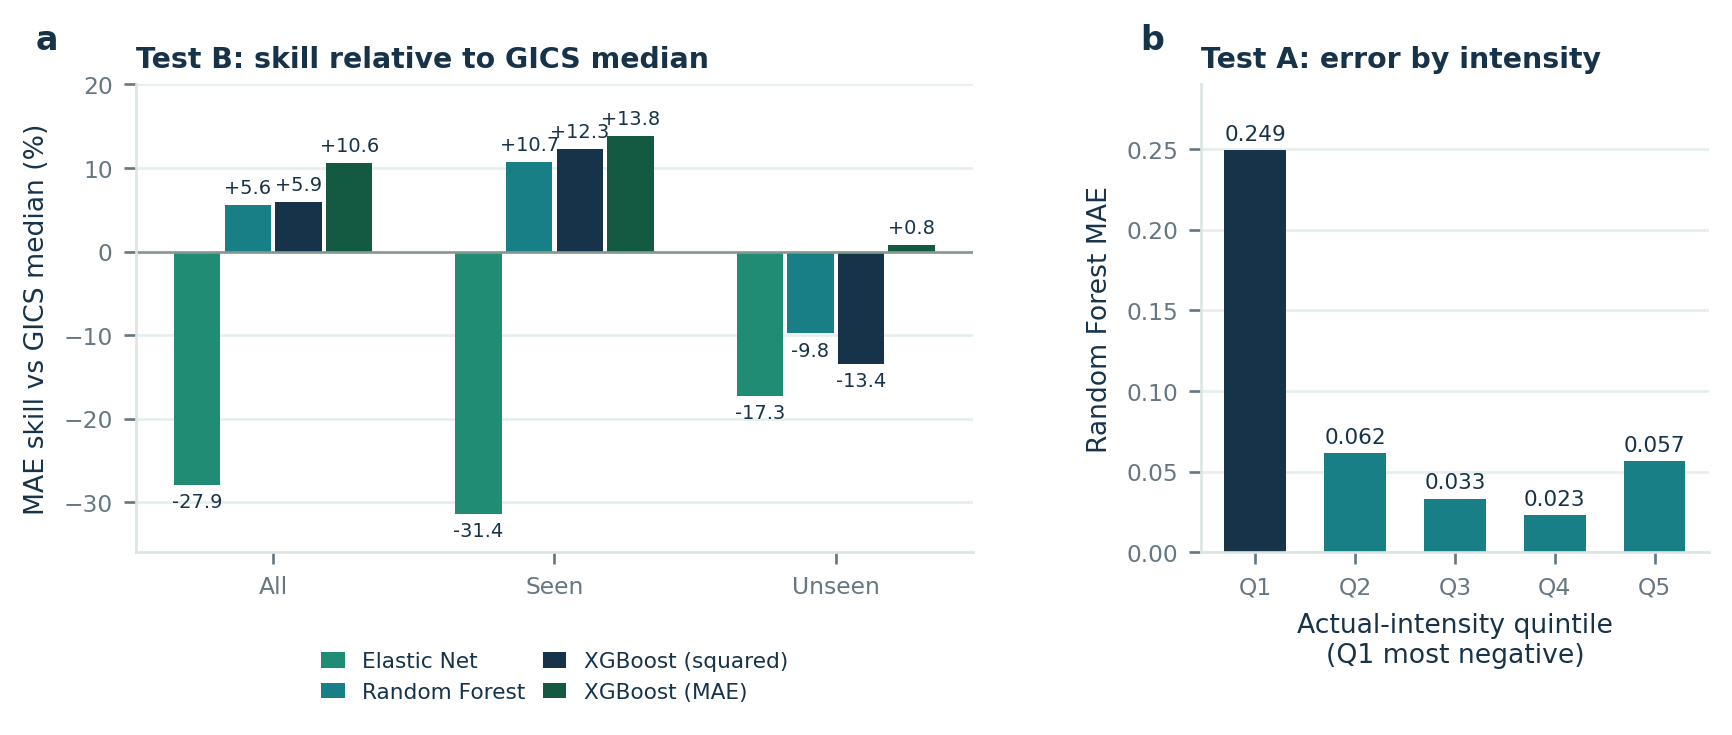

In [ ]:
# Table 1. Prediction performance across unseen-firm and later-period tests.
from sklearn.metrics import mean_absolute_error, r2_score
for v in ("pB", "yB", "oofA"):
    assert v in globals(), f"Run the loss-matched XGBoost cell first ({v} is missing)"

MAE_LOSS = f"{BOOST} (MAE loss)"
masksB = {name: np.asarray(mk, bool) for name, mk in sample_defs_B}
yA = df[TARGET].values
gicsB = np.asarray(prB["Sub-industry median (GICS)"])
SAMPLES = [
    ("All 2017-2019", "All"),
    ("Seen firms", "Seen"),
    ("Unseen firms", "Unseen")
]

rows = []
for m in MODELS:
    rows.append({
        "Model": m,
        "Test A: MAE": get(A, m, "MAE"),
        "Test A: R²": get(A, m, "R2"),
        "Test B: MAE, all": get(B[B["sample"] == "All 2017-2019"], m, "MAE"),
        "Test B: MAE, seen": get(B[B["sample"] == "Seen firms"], m, "MAE"),
        "Test B: MAE, unseen": get(B[B["sample"] == "Unseen firms"], m, "MAE"),
    })
rows.append({
    "Model": MAE_LOSS,
    "Test A: MAE": mean_absolute_error(yA, oofA),
    "Test A: R²": r2_score(yA, oofA),
    "Test B: MAE, all": mean_absolute_error(yB[masksB["All 2017-2019"]], pB[masksB["All 2017-2019"]]),
    "Test B: MAE, seen": mean_absolute_error(yB[masksB["Seen firms"]], pB[masksB["Seen firms"]]),
    "Test B: MAE, unseen": mean_absolute_error(yB[masksB["Unseen firms"]], pB[masksB["Unseen firms"]]),
})
T1 = pd.DataFrame(rows).set_index("Model")
T1.round(4).to_csv(f"{OUT_DIR}/table1_prediction_accuracy.csv")
mae_cols = [c for c in T1.columns if "MAE" in c]
display(booktabs_style(T1.reset_index(), {c: "{:.3f}" for c in T1.columns}, highlight_cols=mae_cols))

# Figure 1: prediction skill and error distribution.
skill_rows = []
for model in MODELS[2:]:
    label = f"{model} (squared loss)" if model == BOOST else model
    for sample_name, sample_label in SAMPLES:
        row = B[(B["sample"] == sample_name) & (B.model == model)].iloc[0]
        skill_rows.append({
            "sample": sample_label,
            "model": label,
            "skill_pct": 100 * row["MAE_skill_vs_GICS_median"]
        })

loss_rows = []
for sample_name, sample_label in SAMPLES:
    mk = masksB[sample_name]
    base_mae = mean_absolute_error(yB[mk], gicsB[mk])
    model_mae = mean_absolute_error(yB[mk], pB[mk])
    loss_rows.append({
        "sample": sample_label,
        "model": MAE_LOSS,
        "skill_pct": 100 * (1 - model_mae / base_mae)
    })
skill_rows.extend(loss_rows)
skill_df = pd.DataFrame(skill_rows)
skill_order = ["All", "Seen", "Unseen"]
model_order = ["Elastic Net", "Random Forest", f"{BOOST} (squared loss)", MAE_LOSS]
skill_palette = [COLORS["green"], COLORS["teal"], COLORS["navy"], COLORS["forest"]]

mp = cns.multipanel(max_width=183, unit="mm")
ax_a = mp.panel("a", width=78, height=55, margin_bottom=22)
cns.barplot(
    data=skill_df, x="sample", y="skill_pct", hue="model",
    order=skill_order, hue_order=model_order, palette=skill_palette,
    errorbar=None, ax=ax_a
)
ax_a.axhline(0, color=COLORS["gray"], linewidth=0.7)
ax_a.set_xlabel("Test B sample")
ax_a.set_ylabel("MAE skill vs GICS median (%)")
ax_a.set_title("Later-period prediction skill", loc="left")
ax_a.set_ylim(-36, 20)
ax_a.legend(frameon=False, fontsize=6, ncol=2, loc="upper center",
            bbox_to_anchor=(0.5, -0.27), handlelength=1.0, columnspacing=0.8)

q_plot = Q.copy()
q_plot["quintile"] = pd.Categorical(
    q_plot["quintile"],
    categories=["Q1 most negative", "Q2", "Q3", "Q4", "Q5 closest to 0"],
    ordered=True
)
ax_b = mp.panel("b", width=62, height=55, margin_bottom=22, margin_right=0)
cns.barplot(
    data=q_plot, x="quintile", y="MAE",
    order=["Q1 most negative", "Q2", "Q3", "Q4", "Q5 closest to 0"],
    palette=[COLORS["navy"], COLORS["teal"], COLORS["teal"], COLORS["teal"], COLORS["teal"]],
    errorbar=None, ax=ax_b
)
ax_b.set_xlabel("Actual-intensity quintile")
ax_b.set_ylabel(f"{BEST} MAE")
ax_b.set_title("Error across Test A intensity", loc="left")
ax_b.set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"])
ax_b.set_ylim(0, 0.29)
for container in ax_b.containers:
    ax_b.bar_label(container, fmt="%.3f", padding=2, fontsize=6)

cns.savefig(f"{OUT_DIR}/figure1_prediction.pdf")
cns.savefig(f"{OUT_DIR}/figure1_prediction.svg")
cns.savefig(f"{OUT_DIR}/figure1_prediction.png", dpi=300)
display(ax_a.figure)


**Figure 1 | Tree-based models improve on the GICS median for seen firms, while gains for unseen firms are limited; prediction error is concentrated in the most-negative intensity quintile.** a, Test B MAE skill relative to the GICS sub-industry median (%) for all, seen and unseen firms; positive values indicate lower MAE than the benchmark. b, Random Forest MAE across Test A actual-intensity quintiles (Q1, most negative; Q5, closest to zero). Test A: five-fold GroupKFold by company, n = 14,015 firm-year observations from 2,485 companies; each quintile contains 2,803 observations. Test B: training period 2010–2016 and test period 2017–2019 (n = 4,931 firm-year observations; 1,647 seen and 493 unseen companies). MAE, mean absolute error; GICS, Global Industry Classification Standard.

**Table 2. Historical firm-level baselines for companies seen in Test B (2017–2019).** Firm-history predictions use each company's 2010–2016 mean, median or last observed target value.

In [ ]:
# Table 2. Historical firm-level baselines for companies seen in Test B.
T2 = FIRM_BASE.rename(columns={
    "model": "Model",
    "firm_balanced_MAE": "Firm-balanced MAE",
    "R2": "R²",
    "MAE_skill_vs_GICS_median": "MAE skill vs GICS median"
})
display(booktabs_style(T2, {
    "MAE": "{:.3f}",
    "Firm-balanced MAE": "{:.3f}",
    "RMSE": "{:.3f}",
    "R²": "{:.3f}",
    "MAE skill vs GICS median": "{:+.1%}"
}, highlight_cols=["MAE"]))


Model,MAE,Firm-balanced MAE,RMSE,R²,MAE skill vs GICS median
Firm's last observed value,0.035,0.038,0.123,0.780,+53.1%
Firm's own median (2010-2016),0.037,0.040,0.127,0.766,+50.0%
Firm's own mean (2010-2016),0.038,0.040,0.127,0.765,+49.4%
XGBoost,0.065,0.067,0.161,0.622,+12.3%
Random Forest,0.067,0.068,0.165,0.603,+10.7%
Sub-industry median (GICS),0.075,0.076,0.201,0.415,+0.0%
Industry median (Exiobase),0.081,0.082,0.214,0.335,-8.1%
Elastic Net,0.098,0.100,0.197,0.435,-31.4%


**Table 3. Feature-family ablation across Test A and Test B.** The full specification includes GICS sub-industry, Exiobase industry, country and year.

In [ ]:
# Table 3. Feature-family ablation across Test A and Test B.
T3 = ABLATION.rename(columns={
    "model": "Model",
    "setup": "Feature setup",
    "A MAE": "Test A MAE",
    "A R2": "Test A R²",
    "B MAE": "Test B MAE",
    "B R2": "Test B R²"
})
display(booktabs_style(T3, {
    "Test A MAE": "{:.4f}",
    "Test A R²": "{:.4f}",
    "Test B MAE": "{:.4f}",
    "Test B R²": "{:.4f}"
}))


Model,Feature setup,Test A MAE,Test A R²,Test B MAE,Test B R²
Random Forest,All 4 features,0.0848,0.4176,0.0785,0.5214
Random Forest,Without country,0.0911,0.3866,0.0912,0.4139
Random Forest,Without year,0.0862,0.4183,0.0762,0.5154
Random Forest,Sector only (GICS + Exiobase),0.0898,0.4051,0.0892,0.4055
XGBoost,All 4 features,0.0878,0.3806,0.0783,0.5143
XGBoost,Without country,0.0889,0.4092,0.0913,0.4146
XGBoost,Without year,0.0880,0.3793,0.0769,0.5081
XGBoost,Sector only (GICS + Exiobase),0.0891,0.4129,0.0887,0.4094


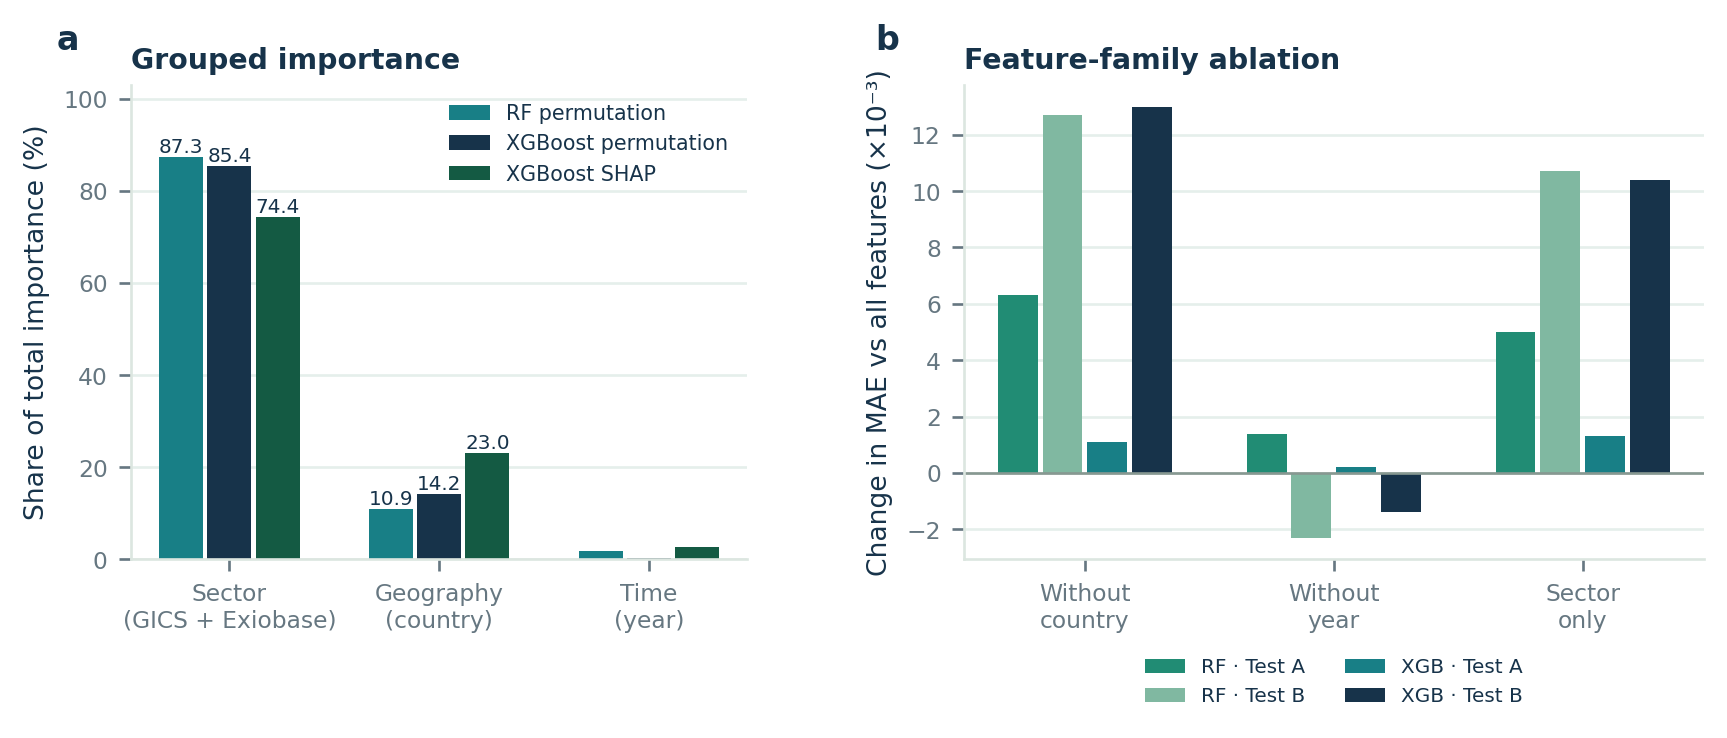

In [ ]:
# Figure 2: grouped feature importance and feature-family ablation.
imp_rows = []
for family in BLOCKS:
    imp_rows.append({
        "family": family,
        "method": "Random Forest permutation",
        "share_pct": float(share(imp["Random Forest"]).loc[family])
    })
    imp_rows.append({
        "family": family,
        "method": f"{BOOST} permutation",
        "share_pct": float(share(imp[BOOST]).loc[family])
    })
if shap_tab is not None:
    shap_share = share(shap_tab.iloc[:, 0])
    for family in BLOCKS:
        imp_rows.append({
            "family": family,
            "method": f"{BOOST} SHAP",
            "share_pct": float(shap_share.loc[family])
        })
imp_long = pd.DataFrame(imp_rows)
family_order = list(BLOCKS.keys())
method_order = ["Random Forest permutation", f"{BOOST} permutation", f"{BOOST} SHAP"]
importance_palette = [COLORS["teal"], COLORS["navy"], COLORS["forest"]]

base_rows = ABLATION[ABLATION["setup"] == "All 4 features"].set_index("model")
ablation_rows = []
setup_order = [
    "Without country",
    "Without year",
    "Sector only (GICS + Exiobase)"
]
for model in ("Random Forest", BOOST):
    for setup in setup_order:
        row = ABLATION[(ABLATION.model == model) & (ABLATION.setup == setup)].iloc[0]
        base = base_rows.loc[model]
        ablation_rows.extend([
            {
                "feature_removed": setup,
                "series": f"{'RF' if model == 'Random Forest' else 'XGBoost'} · Test A",
                "delta_mae_milli": 1000 * (row["A MAE"] - base["A MAE"])
            },
            {
                "feature_removed": setup,
                "series": f"{'RF' if model == 'Random Forest' else 'XGBoost'} · Test B",
                "delta_mae_milli": 1000 * (row["B MAE"] - base["B MAE"])
            }
        ])
ablation_long = pd.DataFrame(ablation_rows)
ablation_series_order = ["RF · Test A", "RF · Test B", "XGBoost · Test A", "XGBoost · Test B"]
ablation_palette = [COLORS["green"], COLORS["sage"], COLORS["teal"], COLORS["navy"]]

mp = cns.multipanel(max_width=183, unit="mm")
ax_a = mp.panel("a", width=75, height=56, margin_bottom=20)
cns.barplot(
    data=imp_long, x="family", y="share_pct", hue="method",
    order=family_order, hue_order=method_order,
    palette=importance_palette, errorbar=None, ax=ax_a
)
ax_a.set_xticklabels(["Sector\n(GICS + Exiobase)", "Geography\n(country)", "Time\n(year)"])
ax_a.set_xlabel("")
ax_a.set_ylabel("Share of total importance (%)")
ax_a.set_title("Grouped permutation and SHAP importance", loc="left")
ax_a.set_ylim(0, 103)
ax_a.legend(frameon=False, fontsize=5.8, loc="upper right")

ax_b = mp.panel("b", width=75, height=56, margin_bottom=20, margin_right=0)
cns.barplot(
    data=ablation_long, x="feature_removed", y="delta_mae_milli",
    hue="series", order=setup_order, hue_order=ablation_series_order,
    palette=ablation_palette, errorbar=None, ax=ax_b
)
ax_b.axhline(0, color=COLORS["gray"], linewidth=0.7)
ax_b.set_xticklabels(["Without\ncountry", "Without\nyear", "Sector\nonly"])
ax_b.set_xlabel("")
ax_b.set_ylabel("Change in MAE vs all features (×10⁻³)")
ax_b.set_title("Feature-family ablation", loc="left")
ax_b.legend(frameon=False, fontsize=5.8, ncol=2, loc="upper center",
            bbox_to_anchor=(0.5, -0.23), handlelength=1.0, columnspacing=0.8)

cns.savefig(f"{OUT_DIR}/figure2_feature_importance_ablation.pdf")
cns.savefig(f"{OUT_DIR}/figure2_feature_importance_ablation.svg")
cns.savefig(f"{OUT_DIR}/figure2_feature_importance_ablation.png", dpi=300)
display(ax_a.figure)


**Figure 2 | Sector is the largest feature-importance family, and removing country produces the largest Test B increase in MAE.** a, Relative grouped importance from Random Forest permutation, XGBoost permutation and grouped XGBoost SHAP; Sector combines GICS sub-industry and Exiobase industry, Geography represents country, and Time represents year. b, Change in MAE relative to the all-feature model (×10⁻³) after removing country, removing year or retaining sector features only; positive values indicate higher error. Test A uses five-fold GroupKFold by company (n = 14,015 firm-year observations); Test B trains on 2010–2016 and tests on 2017–2019 (n = 4,931). SHAP, SHapley Additive exPlanations; MAE, mean absolute error.

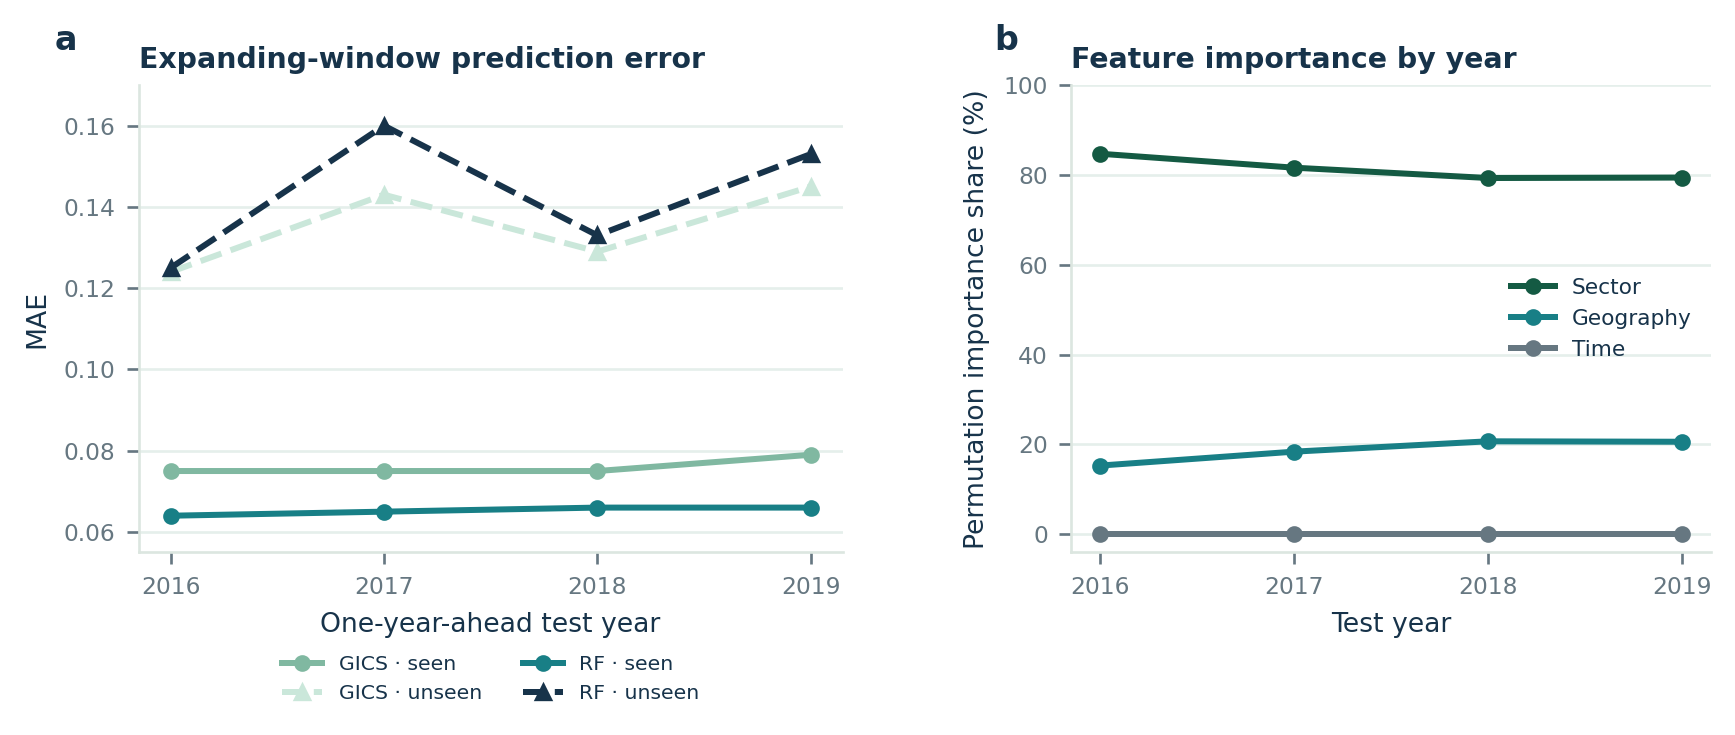

In [ ]:
# Figure 3: expanding-window prediction error and feature importance by test year.
bt_plot = BACKTEST[
    BACKTEST.model.isin(["Sub-industry median (GICS)", "Random Forest"])
    & BACKTEST["sample"].isin(["Seen firms", "Unseen firms"])
].copy()
bt_plot["series"] = bt_plot.apply(
    lambda r: (
        "GICS · " + ("seen" if r["sample"] == "Seen firms" else "unseen")
        if r["model"] == "Sub-industry median (GICS)"
        else "RF · " + ("seen" if r["sample"] == "Seen firms" else "unseen")
    ),
    axis=1
)
bt_order = ["GICS · seen", "GICS · unseen", "RF · seen", "RF · unseen"]
bt_palette = [COLORS["sage"], COLORS["mint"], COLORS["teal"], COLORS["navy"]]

imp_time_long = (
    IMP_TIME.rename_axis("family")
    .reset_index()
    .melt(id_vars="family", var_name="test_year", value_name="share_pct")
)
imp_time_long["test_year"] = imp_time_long["test_year"].astype(int)
imp_time_long["family"] = imp_time_long["family"].map({
    "Sector (GICS + Exiobase)": "Sector",
    "Geography (country)": "Geography",
    "Time (year)": "Time"
})

mp = cns.multipanel(max_width=183, unit="mm")
ax_a = mp.panel("a", width=75, height=56, margin_bottom=21)
cns.lineplot(
    data=bt_plot, x="test_year", y="MAE", hue="series", style="series",
    hue_order=bt_order, style_order=bt_order, palette=bt_palette,
    markers=True, dashes=False, estimator=None, errorbar=None, ax=ax_a
)
ax_a.set_xlabel("One-year-ahead test year")
ax_a.set_ylabel("MAE")
ax_a.set_title("Expanding-window prediction error", loc="left")
ax_a.set_xticks([2016, 2017, 2018, 2019])
ax_a.set_ylim(0.055, 0.17)
ax_a.legend(frameon=False, fontsize=5.8, ncol=2, loc="upper center",
            bbox_to_anchor=(0.5, -0.24), handlelength=1.1, columnspacing=0.8)

ax_b = mp.panel("b", width=75, height=56, margin_bottom=21, margin_right=0)
cns.lineplot(
    data=imp_time_long, x="test_year", y="share_pct", hue="family",
    style="family", hue_order=["Sector", "Geography", "Time"],
    style_order=["Sector", "Geography", "Time"],
    palette=[COLORS["forest"], COLORS["teal"], COLORS["gray"]],
    markers=True, dashes=False, estimator=None, errorbar=None, ax=ax_b
)
ax_b.set_xlabel("Test year")
ax_b.set_ylabel("Permutation importance share (%)")
ax_b.set_title("Feature importance by year", loc="left")
ax_b.set_xticks([2016, 2017, 2018, 2019])
ax_b.set_ylim(-4, 100)
ax_b.legend(frameon=False, fontsize=6.2, loc="center right")

cns.savefig(f"{OUT_DIR}/figure3_temporal_robustness.pdf")
cns.savefig(f"{OUT_DIR}/figure3_temporal_robustness.svg")
cns.savefig(f"{OUT_DIR}/figure3_temporal_robustness.png", dpi=300)
display(ax_a.figure)


**Figure 3 | Prediction errors remain lower for seen firms than unseen firms across one-year-ahead tests, while sector remains the largest importance family.** a, MAE for the GICS sub-industry median and Random Forest among seen and unseen firms in expanding-window tests for 2016–2019; each test year is predicted using only earlier years. b, Random Forest grouped permutation-importance shares for Sector, Geography and Time across the same test years. The all-firm test samples contain 1,612, 1,653, 1,615 and 1,663 firm-year observations in 2016, 2017, 2018 and 2019, respectively. No confidence intervals are plotted. MAE, mean absolute error; GICS, Global Industry Classification Standard; RF, Random Forest.

**Table 4. Low-imputation sensitivity check.** The subset contains 7,885 firm-year observations with `pct_imputed` ≤ 5%; `pct_imputed` is used only to define the subset and is not a model predictor.

In [ ]:
# Table 4. Low-imputation sensitivity check (pct_imputed ≤ 5%).
T4 = LOW.rename(columns={
    "model": "Model",
    "R2": "R²",
    "MAE_skill_vs_industry_median": "MAE skill vs industry median",
    "MAE_skill_vs_GICS_median": "MAE skill vs GICS median"
})
display(booktabs_style(T4, {
    "MAE": "{:.4f}",
    "R²": "{:.4f}",
    "MAE skill vs industry median": "{:+.1%}",
    "MAE skill vs GICS median": "{:+.1%}"
}, highlight_cols=["MAE"]))


Model,MAE,R²,MAE skill vs industry median,MAE skill vs GICS median
Industry median (Exiobase),0.1051,0.3427,+0.0%,+2.1%
Sub-industry median (GICS),0.1073,0.3649,-2.1%,+0.0%
Elastic Net,0.1169,0.4204,-11.2%,-8.9%
Random Forest,0.1093,0.3924,-4.0%,-1.8%
XGBoost,0.1100,0.3665,-4.6%,-2.4%


### E. Export

The workbook contains the full evaluation outputs, fold-level results, feature-importance summaries, temporal backtest and sensitivity analysis.

CNSPlots reference: Rashidi, F. (2026). *cnsplots* (version 0.8.0). https://pypi.org/project/cnsplots/0.8.0/.

In [ ]:
# Export
readme = pd.DataFrame({
    "item": [
        "Data", "Target", "Predictors", "Benchmarks", "Models",
        "Test A", "Test B", "Temporal backtest", "Counts", "Firm-balanced sensitivity", "Skill", "Seed",
    ],
    "value": [
        "cleaned 0% (14,015 rows)",
        TARGET,
        ", ".join(FEATS) + " (pct_imputed not used as predictor)",
        "industry median (Exiobase), sub-industry median (GICS)",
        f"Elastic Net, Random Forest, {BOOST}",
        "5-fold GroupKFold by company; Elastic Net/XGBoost tuned only inside each outer training fold",
        "train 2010-2016, tune only within 2010-2016, test 2017-2019; all/seen/unseen",
        "expanding windows through 2015/2016/2017/2018 -> next year; tune only on past data; all/seen/unseen",
        "n_obs = company-year observations; n_firms = unique companies",
        "firm_balanced_MAE averages MAE within each firm first, then averages firms equally; reported for Test A, Test B, and temporal backtests",
        "both standard MAE skill and firm-balanced MAE skill are reported vs industry and GICS medians",
        SEED,
    ],
})

param_rows = []
for yr, pars in BACKTEST_PARAMS.items():
    for model_name, p in pars.items():
        param_rows.append({
            "test_year": yr,
            "model": model_name,
            "params": json.dumps(p)
        })
BACKTEST_PARAM_TABLE = pd.DataFrame(param_rows)

sheets = [
    ("README", readme),
    ("RQ3_A_unseen_firms", A),
    ("RQ3_A_per_fold", pd.DataFrame(fold_rows)),
    ("RQ3_B_future", B),
    ("RQ3_error_by_quintile", Q),
    ("RQ3_perm_importance", imp_tab.reset_index()),
    ("RQ3_ablation", ABLATION),
    ("RQ3_backtest", BACKTEST),
    ("RQ3_backtest_params", BACKTEST_PARAM_TABLE),
    ("RQ3_importance_by_year", IMP_TIME.reset_index()),
    ("RQ3_low_imputation", LOW),
    ("RQ3_prediction_summary", T1.reset_index()),
    ("RQ3_B_history_baselines", FIRM_BASE),
] + ([("RQ3_SHAP", shap_tab.reset_index())] if shap_tab is not None else [])

with pd.ExcelWriter(f"{OUT_DIR}/RQ3_results.xlsx", engine="openpyxl") as xw:
    for name, tbl in sheets:
        tbl.round(5).to_excel(xw, sheet_name=name[:31], index=False)

print("saved to", OUT_DIR, "| total", round(time.time() - t0), "s")